# 02 — Baselines com TF-IDF

Continuação de `01-sanjos-eda.ipynb` (etapas 1–3 do checklist).

Esse segundo notebook aborda:

  4. Preparar os dados para os algorítimos.
    - Conversão de tipos
  5. Selecionar modelo e treina-lo.
    - 70/30, cross-validation
  
`Refazer passos 4-5 e testar diferentes propostas.`

  6. Otimizar modelo.
    - GridSearch
  7. Organizar apresentação da solução

## Setup

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import FeatureUnion, Pipeline, make_pipeline, make_union
from sklearn.svm import LinearSVC

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

SEED = 42
N_JOBS = 4

CAMINHOS_KAGGLE = [Path("/kaggle/input/competitions/name-that-llm"), Path("/kaggle/input/name-that-llm")]
NO_KAGGLE = any(p.exists() for p in CAMINHOS_KAGGLE)
DATA_DIR = next((p for p in CAMINHOS_KAGGLE if p.exists()), Path("../data"))
SAIDA_DIR = Path(".") if NO_KAGGLE else Path("../submissions")

name_llm = pd.read_csv(DATA_DIR / "train.csv")

## 4. Preparar os dados para os algoritmos

### 4.1 Separar entrada, rótulo e grupos

In [2]:
x = name_llm["text"]
y = name_llm["model"]
groups = name_llm["prompt_id"]

### 4.2 Conversão de tipos: texto → números

O modelo não aceita texto. O `TfidfVectorizer` transforma cada texto num vetor numérico e fica **dentro do pipeline**, para ser ajustado só nos dados de treino de cada fold. Dois vetorizadores são usados:

- **palavras**: capta o vocabulário preferido de cada LLM;
- **caracteres** (n-gramas de 2 a 5): capta estilo, como pontuação, sufixos e espaçamento.

In [3]:
def vetorizador_palavras():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)


def vetorizador_caracteres(analyzer="char_wb", lowercase=True):
    return TfidfVectorizer(analyzer=analyzer, ngram_range=(2, 5), sublinear_tf=True, lowercase=lowercase)

## 5. Selecionar modelo e treiná-lo

### 5.1 Divisão 70/30 por prompt

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED)
idx_treino, idx_teste = next(gss.split(x, y, groups=groups))
x_train, x_test = x.iloc[idx_treino], x.iloc[idx_teste]
y_train, y_test = y.iloc[idx_treino], y.iloc[idx_teste]

O holdout (`x_test`, `y_test`) fica reservado para a análise de erros da seção 7.1.

### 5.2 Validação cruzada por prompt

Cada `prompt_id` foi respondido pelos 18 modelos, e o teste escondido deve usar prompts novos. A validação separa os dados **por prompt** (`GroupKFold`) para a nota não sair otimista. Como os folds são sempre os mesmos, os experimentos podem ser comparados fold a fold.

In [5]:
CV = GroupKFold(n_splits=5)
resultados = []


def avaliar(vetorizador, modelo, nome):
    pipeline = make_pipeline(vetorizador, modelo)
    scores = cross_val_score(pipeline, x, y, groups=groups, cv=CV,
                             scoring="balanced_accuracy", n_jobs=N_JOBS)
    resultados.append({"experimento": nome, "media": scores.mean(), "desvio": scores.std(),
                       **{f"fold_{i + 1}": s for i, s in enumerate(scores)}})
    print(f"{nome}: {scores.mean():.2%} (+/- {scores.std():.2%})  folds={np.round(scores, 4)}")
    return scores

### 5.3 TF-IDF de palavras + regressão logística

In [6]:
avaliar(TfidfVectorizer(), LogisticRegression(max_iter=1000), "palavras + LogisticRegression");

palavras + LogisticRegression: 26.86% (+/- 0.89%)  folds=[0.2593 0.2759 0.2667 0.2815 0.2595]


### 5.4 TF-IDF de caracteres + regressão logística

In [7]:
avaliar(vetorizador_caracteres(), LogisticRegression(max_iter=1000), "caracteres + LogisticRegression");

caracteres + LogisticRegression: 29.63% (+/- 0.53%)  folds=[0.2926 0.2889 0.3    0.2963 0.304 ]


### 5.5 TF-IDF de palavras + caracteres + regressão logística

In [8]:
avaliar(make_union(TfidfVectorizer(), vetorizador_caracteres()), LogisticRegression(max_iter=1000),
        "palavras + caracteres + LogisticRegression");

palavras + caracteres + LogisticRegression: 30.89% (+/- 1.33%)  folds=[0.2926 0.2981 0.3074 0.3296 0.3169]


### 5.6 Comparação de modelos (palavras + caracteres)

In [9]:
modelos = {
    "LinearSVC": LinearSVC(),
    "SGDClassifier": SGDClassifier(random_state=SEED),
    "ComplementNB": ComplementNB(),
    "RidgeClassifier": RidgeClassifier(),
}
for nome, modelo in modelos.items():
    avaliar(make_union(TfidfVectorizer(), vetorizador_caracteres()), modelo, f"palavras + caracteres + {nome}")

palavras + caracteres + LinearSVC: 30.15% (+/- 2.20%)  folds=[0.3093 0.287  0.2667 0.3278 0.3169]


palavras + caracteres + SGDClassifier: 28.15% (+/- 1.76%)  folds=[0.2889 0.2907 0.2481 0.2815 0.2985]


palavras + caracteres + ComplementNB: 24.56% (+/- 1.31%)  folds=[0.2241 0.2426 0.25   0.2648 0.2464]


palavras + caracteres + RidgeClassifier: 29.74% (+/- 1.73%)  folds=[0.3074 0.287  0.2685 0.3148 0.3094]


### 5.7 Tabela de resultados

In [10]:
tabela = pd.DataFrame(resultados).sort_values("media", ascending=False).reset_index(drop=True)
colunas_num = [col for col in tabela.columns if col != "experimento"]
tabela[colunas_num] = (tabela[colunas_num] * 100).round(2)
tabela

,experimento,media,desvio,fold_1,fold_2,fold_3,fold_4,fold_5
0,palavras + caracteres + LogisticRegression,30.89,1.33,29.26,29.81,30.74,32.96,31.69
1,palavras + caracteres + LinearSVC,30.15,2.20,30.93,28.70,26.67,32.78,31.69
2,palavras + caracteres + RidgeClassifier,29.74,1.73,30.74,28.70,26.85,31.48,30.94
3,caracteres + LogisticRegression,29.63,0.53,29.26,28.89,30.00,29.63,30.40
4,palavras + caracteres + SGDClassifier,28.15,1.76,28.89,29.07,24.81,28.15,29.85
5,palavras + LogisticRegression,26.86,0.89,25.93,27.59,26.67,28.15,25.95
6,palavras + caracteres + ComplementNB,24.56,1.31,22.41,24.26,25.00,26.48,24.64


## 6. Otimizar modelo

### 6.1 GridSearch: vetorizador, modelo, função de custo e penalização

Uma única busca testa ao mesmo tempo:

- **vetorizador de caracteres**: `analyzer` (`char_wb` não cruza palavras; `char` cruza e capta espaçamento e pontuação entre elas) e `lowercase` (desligar preserva o uso de maiúsculas);
- **modelo**: o passo `clf` do pipeline é trocado pela própria busca;
- **função de custo** (`loss`): `hinge` (SVM), `squared_hinge`, `log_loss` (regressão logística), `modified_huber`;
- **penalização**: tipo (`l2`, `l1`, `elasticnet`) e força (`C` = inverso da força; `alpha` = força direta).

O `param_grid` é uma **lista de dicionários**: cada dicionário define um modelo e só os parâmetros que ele aceita. A regressão logística recebe menos combinações porque é o modelo mais lento (cerca de 30 s por treino contra 4–8 s dos outros).

In [11]:
pipeline_busca = Pipeline([
    ("vect", FeatureUnion([
        ("palavras", vetorizador_palavras()),
        ("caracteres", vetorizador_caracteres()),
    ])),
    ("clf", LogisticRegression(max_iter=1000)),
])

grade_vetorizador = {
    "vect__caracteres__analyzer": ["char_wb", "char"],
    "vect__caracteres__lowercase": [True, False],
}

param_grid = [
    {**grade_vetorizador,
     "clf": [LogisticRegression(max_iter=1000)],
     "clf__C": [1, 10]},
    {**grade_vetorizador,
     "clf": [LinearSVC()],
     "clf__loss": ["hinge", "squared_hinge"],
     "clf__C": [0.1, 0.5, 1]},
    {**grade_vetorizador,
     "clf": [SGDClassifier(random_state=SEED)],
     "clf__loss": ["hinge", "log_loss", "modified_huber"],
     "clf__penalty": ["l2", "l1", "elasticnet"],
     "clf__alpha": [1e-5, 1e-4]},
    {**grade_vetorizador,
     "clf": [RidgeClassifier()],
     "clf__alpha": [0.3, 1, 3]},
    {**grade_vetorizador,
     "clf": [ComplementNB()],
     "clf__alpha": [0.1, 0.3, 1]},
]

n_combinacoes = sum(np.prod([len(v) for v in g.values()]) for g in param_grid)
print(f"{n_combinacoes} combinações x {CV.get_n_splits()} folds = {n_combinacoes * CV.get_n_splits()} treinos")

128 combinações x 5 folds = 640 treinos


Em execução local (12 núcleos, `N_JOBS = 4`) a busca leva cerca de meia hora. No Kaggle, `RODAR_GRID = False` usa os melhores parâmetros já encontrados, para a submissão não estourar o tempo.

In [12]:
RODAR_GRID = not NO_KAGGLE

if RODAR_GRID:
    busca = GridSearchCV(pipeline_busca, param_grid, cv=CV, scoring="balanced_accuracy",
                         n_jobs=N_JOBS, refit=True, verbose=1)
    busca.fit(x, y, groups=groups)
    print("Melhor balanced accuracy:", f"{busca.best_score_:.2%}")
    print("Melhores parâmetros:", busca.best_params_)

Fitting 5 folds for each of 128 candidates, totalling 640 fits


Melhor balanced accuracy: 32.52%
Melhores parâmetros: {'clf': LogisticRegression(max_iter=1000), 'clf__C': 10, 'vect__caracteres__analyzer': 'char', 'vect__caracteres__lowercase': False}


### 6.2 Resultados da busca

In [13]:
if RODAR_GRID:
    cv_res = pd.DataFrame(busca.cv_results_)
    cv_res["modelo"] = cv_res["param_clf"].map(lambda m: type(m).__name__)
    colunas_param = [c for c in cv_res.columns if c.startswith("param_") and c != "param_clf"]
    top = cv_res.sort_values("rank_test_score")[["rank_test_score", "modelo", *colunas_param,
                                                   "mean_test_score", "std_test_score", "mean_fit_time"]]
    display(top.head(15))

,rank_test_score,modelo,param_clf__C,param_vect__caracteres__analyzer,param_vect__caracteres__lowercase,param_clf__loss,param_clf__alpha,param_clf__penalty,mean_test_score,std_test_score,mean_fit_time
7,1,LogisticRegression,10.0,char,False,NaN,NaN,NaN,0.325249,0.018642,71.166072
6,2,LogisticRegression,10.0,char,True,NaN,NaN,NaN,0.320434,0.019151,77.922435
5,3,LogisticRegression,10.0,char_wb,False,NaN,NaN,NaN,0.317854,0.014416,66.096437
83,4,SGDClassifier,NaN,char,False,log_loss,0.00010,l2,0.317075,0.018752,10.181369
91,5,SGDClassifier,NaN,char,False,log_loss,0.00010,elasticnet,0.314100,0.024773,17.333312
89,6,SGDClassifier,NaN,char_wb,False,log_loss,0.00010,elasticnet,0.313346,0.019346,10.231533
3,7,LogisticRegression,1.0,char,False,NaN,NaN,NaN,0.313001,0.017533,29.233220
51,8,SGDClassifier,NaN,char,False,log_loss,0.00001,l1,0.312644,0.014077,13.438029
81,9,SGDClassifier,NaN,char_wb,False,log_loss,0.00010,l2,0.312605,0.008721,5.111163
90,9,SGDClassifier,NaN,char,True,log_loss,0.00010,elasticnet,0.312605,0.023767,20.865154


Melhor configuração de cada modelo:

In [14]:
if RODAR_GRID:
    melhor_por_modelo = (cv_res.sort_values("mean_test_score", ascending=False)
                         .groupby("modelo", as_index=False).first()
                         .sort_values("mean_test_score", ascending=False))
    display(melhor_por_modelo[["modelo", *colunas_param, "mean_test_score", "std_test_score"]])

,modelo,param_clf__C,param_vect__caracteres__analyzer,param_vect__caracteres__lowercase,param_clf__loss,param_clf__alpha,param_clf__penalty,mean_test_score,std_test_score
2,LogisticRegression,10.0,char,False,NaN,NaN,NaN,0.325249,0.018642
4,SGDClassifier,NaN,char,False,log_loss,0.0001,l2,0.317075,0.018752
1,LinearSVC,0.5,char,False,squared_hinge,NaN,NaN,0.312273,0.013728
3,RidgeClassifier,NaN,char,False,NaN,1.0000,NaN,0.310051,0.011643
0,ComplementNB,NaN,char,False,NaN,1.0000,NaN,0.258174,0.018911


Efeito do vetorizador (média sobre todos os modelos):

In [15]:
if RODAR_GRID:
    display(cv_res.groupby(["param_vect__caracteres__analyzer", "param_vect__caracteres__lowercase"])
            ["mean_test_score"].agg(["mean", "max"]))

mean  \
param_vect__caracteres__analyzer param_vect__caracteres__lowercase             
char                             False                              0.283576   
                                 True                               0.280345   
char_wb                          False                              0.281338   
                                 True                               0.277692   

                                                                         max  
param_vect__caracteres__analyzer param_vect__caracteres__lowercase            
char                             False                              0.325249  
                                 True                               0.320434  
char_wb                          False                              0.317854  
                                 True                               0.311494

## 7. Organizar apresentação da solução

### 7.1 Análise de erros no holdout

O melhor pipeline é treinado nos 70% de treino e avaliado nos 30% de prompts nunca vistos. A pergunta é se os erros acontecem **dentro da mesma família** de LLMs (Claude com Claude, GPT com GPT).

In [16]:
MELHORES_PARAMS_FIXOS = {
    "clf": LogisticRegression(max_iter=1000),
    "clf__C": 10,
    "vect__caracteres__analyzer": "char",
    "vect__caracteres__lowercase": False,
}

def pipeline_final():
    pipe = Pipeline([
        ("vect", FeatureUnion([("palavras", vetorizador_palavras()), ("caracteres", vetorizador_caracteres())])),
        ("clf", LogisticRegression(max_iter=1000)),
    ])
    params = busca.best_params_ if RODAR_GRID else MELHORES_PARAMS_FIXOS
    return pipe.set_params(**params)


modelo_holdout = pipeline_final().fit(x_train, y_train)
pred_holdout = modelo_holdout.predict(x_test)
print(f"Balanced accuracy no holdout: {balanced_accuracy_score(y_test, pred_holdout):.2%}")
print(classification_report(y_test, pred_holdout, digits=3))

Balanced accuracy no holdout: 30.00%
                        precision    recall  f1-score   support

        claude-fable-5      0.125     0.089     0.104        45
       claude-opus-4-6      0.378     0.311     0.341        45
       claude-opus-4-8      0.231     0.200     0.214        45
         claude-opus-5      0.341     0.622     0.441        45
       claude-sonnet-5      0.324     0.267     0.293        45
gemini-3.1-pro-preview      0.592     0.644     0.617        45
      gemini-3.6-flash      0.358     0.422     0.388        45
      gemini-3.7-flash      0.310     0.400     0.350        45
      gemini-3.8-flash      0.286     0.222     0.250        45
               glm-5.3      0.182     0.089     0.119        45
         glm-5.3-flash      0.182     0.133     0.154        45
               gpt-5.5      0.286     0.267     0.276        45
          gpt-5.6-luna      0.214     0.333     0.261        45
           gpt-5.6-sol      0.188     0.133     0.156        45
  

Erros: 567 de 810; dentro da mesma família: 54.9%


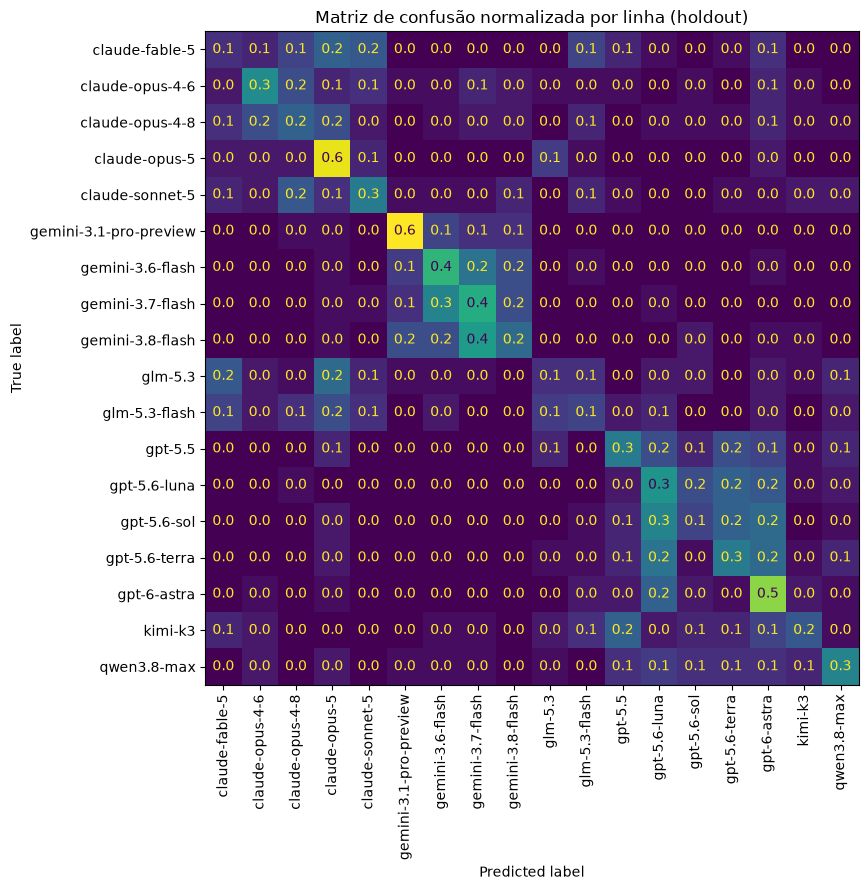

In [17]:
familia = lambda nome: nome.split("-")[0]
erros = y_test != pred_holdout
mesma_familia = y_test[erros].map(familia) == pd.Series(pred_holdout, index=y_test.index)[erros].map(familia)
print(f"Erros: {erros.sum()} de {len(y_test)}; dentro da mesma família: {mesma_familia.mean():.1%}")

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(y_test, pred_holdout, ax=ax, xticks_rotation=90,
                                        normalize="true", values_format=".1f", colorbar=False)
ax.set_title("Matriz de confusão normalizada por linha (holdout)")
plt.tight_layout()
plt.show()

### 7.2 Modelo final e submissão

In [18]:
modelo_final = busca.best_estimator_ if RODAR_GRID else pipeline_final().fit(x, y)

teste = pd.read_csv(DATA_DIR / "test.csv")
submissao = pd.DataFrame({"id": teste["id"], "model": modelo_final.predict(teste["text"])})
SAIDA_DIR.mkdir(parents=True, exist_ok=True)
submissao.to_parquet(SAIDA_DIR / "submission.parquet", index=False)
print(f"submission.parquet salvo com {len(submissao)} linhas em {SAIDA_DIR.resolve()}")
submissao.head()

submission.parquet salvo com 3 linhas em /home/anjos/github/name-that-llm/submissions


,id,model
0,00353fb1c541,gemini-3.6-flash
1,005f5a9a6139,gpt-5.6-terra
2,0062a53d5487,gemini-3.7-flash


### 7.3 Conclusões e próximos passos

**Resultados (balanced accuracy, `GroupKFold` por prompt):**

| Configuração | Média | Desvio |
|---|---|---|
| Palavras + LogisticRegression | 26,86% | 0,89% |
| Caracteres + LogisticRegression | 29,63% | 0,53% |
| Palavras + caracteres + LogisticRegression (padrão) | 30,89% | 1,33% |
| **GridSearch: palavras (1–2) + caracteres `char`, sem lowercase + LogisticRegression `C=10`** | **32,52%** | 1,86% |
| Holdout 30% (prompts nunca vistos), mesma configuração | 30,00% | — |

Chute aleatório: 5,6%.

**O que a busca mostrou (128 combinações, 640 treinos):**

- **Preservar maiúsculas ajuda sempre.** `lowercase=False` ganhou em todas as combinações de analisador, na média e no máximo. O uso de maiúsculas faz parte do estilo de cada LLM.
- **`char` supera `char_wb`.** N-gramas que atravessam palavras captam espaçamento e pontuação entre elas.
- **Regularização mais fraca funcionou melhor na regressão logística** (`C=10` > `C=1`). Como `C=10` é o limite da grade, valores maiores ainda podem render mais.
- **Entre funções de custo, `log_loss` foi a melhor no SGD** (31,71% com penalização `l2`, `alpha=1e-4`). As penalizações `elasticnet` (31,41%) e `l1` (31,26%) ficaram perto da `l2`, dentro do desvio: trocar o tipo de penalização mudou pouco o resultado.
- **Melhor de cada modelo:** LogisticRegression 32,52% · SGDClassifier 31,71% · LinearSVC 31,23% (`squared_hinge`, `C=0.5`) · RidgeClassifier 31,01% · ComplementNB 25,82%. Os quatro primeiros ficam a cerca de 1 desvio entre si.

**Análise de erros (holdout):**

- **55% dos erros acontecem dentro da mesma família** (Claude com Claude, GPT com GPT etc.). Se os erros fossem aleatórios, essa taxa seria ~18%, considerando o tamanho de cada família. O modelo reconhece a família, mas confunde as versões.
- Mais fáceis: `gemini-3.1-pro-preview` (recall 64%) e `claude-opus-5` (62%). Mais difíceis: `claude-fable-5` e `glm-5.3` (9%).

**Próximos passos:**

1. Ampliar `C` (30, 100) e testar n-gramas de caracteres até 6.
2. Features de estilo explícitas (tamanho do texto, travessões, parágrafos) com `ColumnTransformer`.
3. Classificação em dois níveis: primeiro a família, depois a versão.
4. Degrau 2: transformer fine-tunado (os notebooks públicos do topo chegam a ~0,70 com LLMs + LoRA).
